In [1]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats
from cmdstanpy import CmdStanModel
import matplotlib.pyplot as plt
plt.style.use('tableau-colorblind10')

## Kalman filter and smoother

In [2]:
def kalman_filter(Y, c, G, V, F, U, s0, P0):
    T, n = Y.shape
    m = F.shape[0]

    s_pred = np.zeros((T, m))       # s_{t|t-1}
    P_pred = np.zeros((T, m, m))    # P_{t|t-1}
    s_filt = np.zeros((T, m))       # s_{t|t}
    P_filt = np.zeros((T, m, m))    # P_{t|t}
    y_pred = np.zeros((T, n))       # y_{t|t-1}
    Q_pred = np.zeros((T, n, n))    # Q_{t|t-1}

    s_prev, P_prev = s0, P0
    for t in range(T):
        # Predict
        s_pred[t] = F @ s_prev
        P_pred[t] = F @ P_prev @ F.T + U
        y_pred[t] = c + G @ s_pred[t]
        Q_pred[t] = G @ P_pred[t] @ G.T + V

        # Gain
        K = np.linalg.solve(Q_pred[t], G @ P_pred[t]).T

        # Update
        innov = Y[t] - y_pred[t]
        s_filt[t] = s_pred[t] + K @ innov
        P_filt[t] = P_pred[t] - K @ Q_pred[t] @ K.T

        s_prev, P_prev = s_filt[t], P_filt[t]

    return {'s_pred': s_pred, 'P_pred': P_pred,
            's_filt': s_filt, 'P_filt': P_filt,
            'y_pred': y_pred, 'Q_pred': Q_pred}

def kalman_smoother(filt, F):
    s_pred, P_pred = filt['s_pred'], filt['P_pred']
    s_filt, P_filt = filt['s_filt'], filt['P_filt']
    T, m = s_filt.shape

    s_smooth = np.zeros((T, m))     # s_{t|T}
    P_smooth = np.zeros((T, m, m))  # P_{t|T}

    # Initialize at final filtered state
    s_smooth[T - 1] = s_filt[T - 1]
    P_smooth[T - 1] = P_filt[T - 1]
    
    for t in range(T - 2, -1, -1):
        J = np.linalg.solve(P_pred[t + 1], F @ P_filt[t]).T
        s_smooth[t] = s_filt[t] + J @ (s_smooth[t + 1] - s_pred[t + 1])
        P_smooth[t] = P_filt[t] + J @ (P_smooth[t + 1] - P_pred[t + 1]) @ J.T

    return {'s_smooth': s_smooth, 'P_smooth': P_smooth}

## Dynamic factor model

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


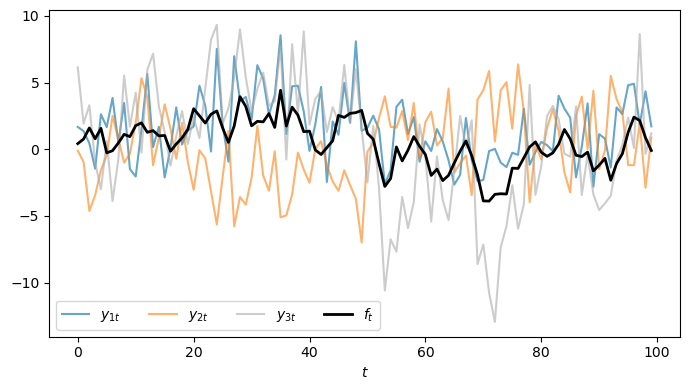

In [3]:
T = 100
a_1 = 0.8
lambdas = np.array([1.0, -1.0, 2.0])
sigmas2 = np.array([4.0, 4.0, 9.0])
c = np.array([1.0, 0.0, 0.0])
rng = np.random.default_rng(seed=31150)

# State space matrices
F = np.array([[a_1]])
U = np.array([[1.0]])
G = lambdas[:, None]
V = np.diag(sigmas2)

# Initial state from stationary distribution
s0 = np.zeros(1)
P0 = np.array([[1 / (1 - a_1**2)]])

f_prev = rng.normal(0, np.sqrt(P0[0, 0]))
f = np.zeros(T)
for t in range(T):
    f[t] = a_1 * f_prev + rng.normal()
    f_prev = f[t]
n = len(lambdas)
Y = c + lambdas * f[:, None] + rng.normal(scale=np.sqrt(sigmas2), size=(T, n))

# Plot
fig, ax = plt.subplots(figsize=(7, 4))
for i in range(n):
    ax.plot(Y[:, i], alpha=0.6, label=f'$y_{{{i+1}t}}$')
ax.plot(f, 'k', linewidth=2, label='$f_t$')
ax.set_xlabel('$t$')
ax.legend(ncol=4)
plt.tight_layout()
fig.savefig('output/factor_sim.eps')
plt.show()

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


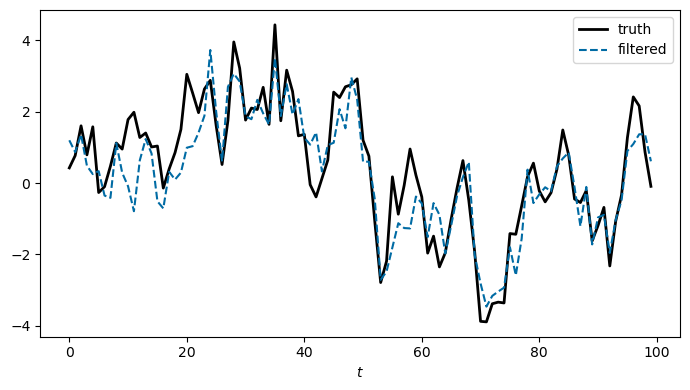

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


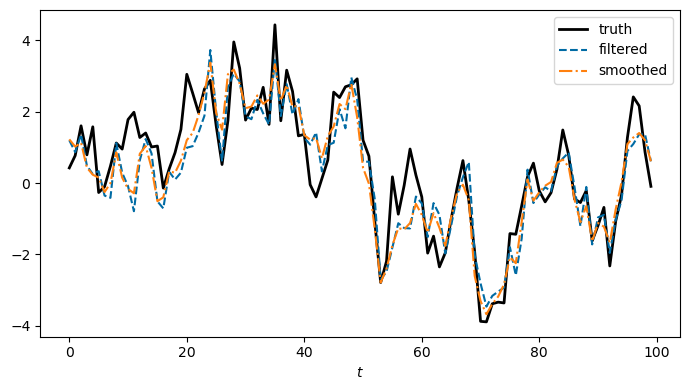

In [4]:
# Apply filter and smoother
filt = kalman_filter(Y, c, G, V, F, U, s0, P0)
smooth = kalman_smoother(filt, F)

# Plot just filter
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(f, 'k', linewidth=2, label='truth')
ax.plot(filt['s_filt'][:, 0], '--', label='filtered')
ax.set_xlabel('$t$')
ax.legend()
plt.tight_layout()
fig.savefig('output/factor_filter.eps')
plt.show()

# Plot both filter and smoother
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(f, 'k', linewidth=2, label='truth')
ax.plot(filt['s_filt'][:, 0], '--', label='filtered')
ax.plot(smooth['s_smooth'][:, 0], '-.', label='smoothed')
ax.set_xlabel('$t$')
ax.legend()
plt.tight_layout()
fig.savefig('output/factor_filter_smooth.eps')
plt.show()

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


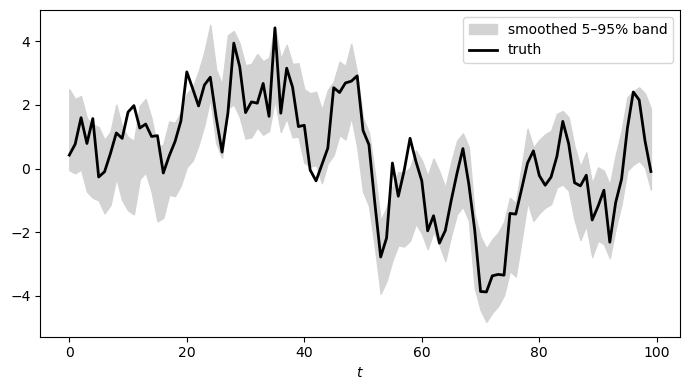

In [5]:
cv = stats.norm.ppf(0.95)
stdev = np.sqrt(smooth['P_smooth'][:, 0, 0])
lo = smooth['s_smooth'][:, 0] - cv * stdev
hi = smooth['s_smooth'][:, 0] + cv * stdev

fig, ax = plt.subplots(figsize=(7, 4))
ax.fill_between(np.arange(T), lo, hi, color='lightgrey', label='smoothed 5–95% band')
ax.plot(f, 'k', linewidth=2, label='truth')
ax.set_xlabel('$t$')
ax.legend()
plt.tight_layout()
fig.savefig('output/factor_smooth_band.eps')
plt.show()

## GDP measurement

In [6]:
# Load data
gdp = pd.read_csv('data/GDPC1.csv', index_col='observation_date', parse_dates=True)
gdi = pd.read_csv('data/A261RX1Q020SBEA.csv', index_col='observation_date', parse_dates=True)
df = pd.concat([gdp.rename(columns={'GDPC1': 'GDP'}),
                gdi.rename(columns={'A261RX1Q020SBEA': 'GDI'})], axis=1)
df = df.loc['1960':'2019']
growth = 400 * np.log(df).diff().dropna()
growth['GDP - GDI'] = growth['GDP'] - growth['GDI']
print(growth.describe())

              GDP         GDI   GDP - GDI
count  239.000000  239.000000  239.000000
mean     2.989405    2.980319    0.009085
std      3.235301    3.159994    1.953780
min     -8.853365   -9.192442   -6.430172
25%      1.397032    1.282381   -1.311526
50%      3.040811    3.235237   -0.009659
75%      4.519602    4.897933    1.228413
max     15.167842   11.874460    5.751909


In [7]:
# Bayesian estimation
y = growth[['GDP', 'GDI']].values
T_gdp = y.shape[0]

# Data for Stan
stan_data = {
    'T': T_gdp,
    'y': y,
    'mu_mean': 3,
    'mu_std': 10,
    'rho_mean': 0.3,
    'rho_std': 1,
    'sigma_scale': 5
}

# Compile and sample
model = CmdStanModel(stan_file='slides14_gdp.stan')
fit = model.sample(data=stan_data, seed=31150, chains=4,
                   iter_warmup=1000, iter_sampling=1000, show_progress=True)

print(fit.summary())

14:03:19 - cmdstanpy - INFO - CmdStan start processing


chain 1:   0%|          | 0/2000 [00:00<?, ?it/s, (Warmup)]

chain 2:   0%|          | 0/2000 [00:00<?, ?it/s, (Warmup)]

chain 3:   0%|          | 0/2000 [00:00<?, ?it/s, (Warmup)]

chain 4:   0%|          | 0/2000 [00:00<?, ?it/s, (Warmup)]

14:03:25 - cmdstanpy - INFO - CmdStan done processing.
14:03:25 - cmdstanpy - WARNING - Non-fatal error during sampling:
Exception: multi_normal_lpdf: Covariance matrix is not symmetric. Covariance matrix[1,2] = inf, but Covariance matrix[2,1] = inf (in 'slides14_gdp.stan', line 48, column 12 to column 49)
	Exception: multi_normal_lpdf: Covariance matrix is not symmetric. Covariance matrix[1,2] = inf, but Covariance matrix[2,1] = inf (in 'slides14_gdp.stan', line 48, column 12 to column 49)
	Exception: multi_normal_lpdf: Covariance matrix is not symmetric. Covariance matrix[1,2] = inf, but Covariance matrix[2,1] = inf (in 'slides14_gdp.stan', line 48, column 12 to column 49)
	Exception: multi_normal_lpdf: Covariance matrix is not symmetric. Covariance matrix[1,2] = inf, but Covariance matrix[2,1] = inf (in 'slides14_gdp.stan', line 48, column 12 to column 49)
	Exception: multi_normal_lpdf: Covariance matrix is not symmetric. Covariance matrix[1,2] = inf, but Covariance matrix[2,1] = in


                  Mean      MCSE    StdDev       MAD          5%         50%  \
lp__       -638.370000  0.040175  1.668750  1.457740 -641.495000 -638.040000   
mu            2.969310  0.005890  0.353748  0.336805    2.370700    2.969400   
rho           0.517305  0.000970  0.062683  0.064073    0.416081    0.517393   
sigma_v[1]    1.559710  0.002103  0.120865  0.119057    1.360640    1.558500   
sigma_v[2]    1.191550  0.002559  0.139131  0.134210    0.962010    1.194780   
sigma_G       2.505770  0.002275  0.145742  0.148457    2.279030    2.500220   
c[1]          2.969310  0.005890  0.353748  0.336805    2.370700    2.969400   
c[2]          2.969310  0.005890  0.353748  0.336805    2.370700    2.969400   
V[1,1]        2.447300  0.006555  0.378641  0.373152    1.851340    2.428930   
V[1,2]        0.000000       NaN  0.000000  0.000000    0.000000    0.000000   
V[2,1]        0.000000       NaN  0.000000  0.000000    0.000000    0.000000   
V[2,2]        1.439140  0.005712  0.325

In [8]:
print(fit.diagnose())

Checking sampler transitions treedepth.
Treedepth satisfactory for all transitions.

Checking sampler transitions for divergences.
No divergent transitions found.

Checking E-BFMI - sampler transitions HMC potential energy.
E-BFMI satisfactory.

Rank-normalized split effective sample size satisfactory for all parameters.

Rank-normalized split R-hat values satisfactory for all parameters.

Processing complete, no problems detected.



The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


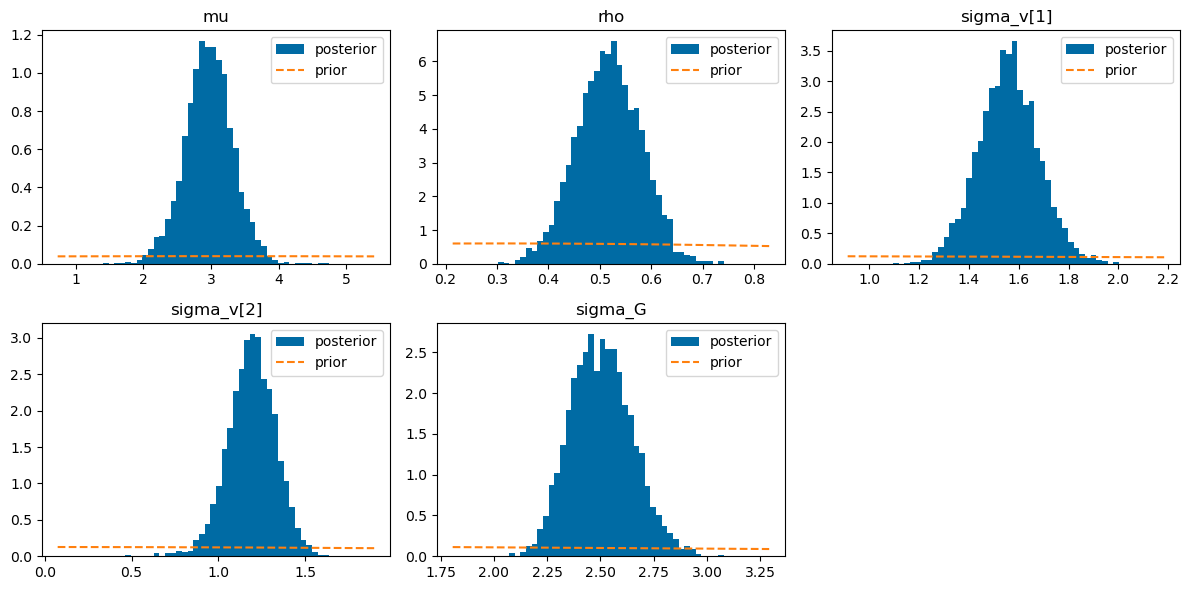

In [9]:
# Posterior vs. prior
params = ['mu', 'rho', 'sigma_v[1]', 'sigma_v[2]', 'sigma_G']
rho_norm = (stats.norm.cdf(1, stan_data['rho_mean'], stan_data['rho_std'])
            - stats.norm.cdf(-1, stan_data['rho_mean'], stan_data['rho_std']))
prior_pdf = {
    'mu':         lambda x: stats.norm.pdf(x, stan_data['mu_mean'], stan_data['mu_std']),
    'rho':        lambda x: stats.norm.pdf(x, stan_data['rho_mean'], stan_data['rho_std']) / rho_norm * ((x > -1) & (x < 1)),
    'sigma_v[1]': lambda x: 2 * stats.cauchy.pdf(x, 0, stan_data['sigma_scale']) * (x >= 0),
    'sigma_v[2]': lambda x: 2 * stats.cauchy.pdf(x, 0, stan_data['sigma_scale']) * (x >= 0),
    'sigma_G':    lambda x: 2 * stats.cauchy.pdf(x, 0, stan_data['sigma_scale']) * (x >= 0),
}

draws = fit.draws_pd()

fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, name in zip(axes.flat, params):
    draws_p = draws[name].values
    lo, hi = draws_p.min(), draws_p.max()
    pad = 0.2 * (hi - lo)
    grid = np.linspace(lo - pad, hi + pad, 400)
    ax.hist(draws_p, bins=40, density=True, label='posterior')
    ax.plot(grid, prior_pdf[name](grid), '--', label='prior')
    ax.set_title(name)
    ax.legend()
axes.flat[5].axis('off')
plt.tight_layout()
fig.savefig('output/factor_gdp_posterior_param.eps')
plt.show()

In [10]:
# Posterior mean E[mu + s_t | data]
draws_df = fit.draws_pd()
n_draws = len(draws_df)
G_mat = np.array([[1.0], [1.0]])
paths = np.zeros((n_draws, T_gdp))

for i in range(n_draws):
    # Extract parameter draw
    mu_d  = draws_df['mu'].iloc[i]
    rho_d = draws_df['rho'].iloc[i]
    sv_d  = np.array([draws_df['sigma_v[1]'].iloc[i], draws_df['sigma_v[2]'].iloc[i]])
    sG_d  = draws_df['sigma_G'].iloc[i]

    # Define state space matrices
    c_d  = np.array([mu_d, mu_d])
    V_d  = np.diag(sv_d**2)
    F_d  = np.array([[rho_d]])
    U_d  = np.array([[sG_d**2]])
    s0_d = np.zeros(1)
    P0_d = np.array([[sG_d**2 / (1 - rho_d**2)]])

    # Kalman smoother
    sm_d = kalman_smoother(kalman_filter(y, c_d, G_mat, V_d, F_d, U_d, s0_d, P0_d), F_d)
    paths[i] = mu_d + sm_d['s_smooth'][:, 0]

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


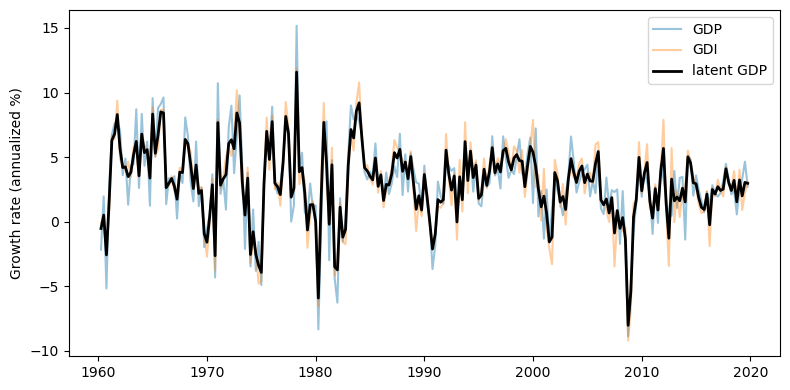

In [11]:
# Plot
dates = growth[['GDP', 'GDI']].index
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(dates, y[:, 0], alpha=0.4, label='GDP')
ax.plot(dates, y[:, 1], alpha=0.4, label='GDI')
ax.plot(dates, paths.mean(axis=0), 'k', linewidth=2, label='latent GDP')
ax.set_ylabel('Growth rate (annualized %)')
ax.legend()
plt.tight_layout()
fig.savefig('output/factor_gdp_posterior_latent.eps')
plt.show()